<a href="https://colab.research.google.com/github/ra-jash-ree/ML-Lab-4NI24CI083/blob/main/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: import all the libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

#Step 2: Read the csv file

data = pd.read_csv('student_data.csv')
print(data)
print(data.head()) #gives first five rows along with the column names


   Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result
0   18           2          75           80.0               70   Pass
1   19           5          88            NaN               89   Pass
2   18           3          89           90.0               65   Pass
3   20           1          75           80.0               70   Pass
4   18           2          77           80.0               70   Pass
5   18           2          78           80.0               70   Pass
6   18           3          89           90.0               65   Pass
7   18           3          89           90.0               65   Pass
8   18           3          89           90.0               65   Pass
9   18           3          89           90.0               65   Pass
   Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result
0   18           2          75           80.0               70   Pass
1   19           5          88            NaN               89   Pass
2   18           3  

In [ ]:
print(data.shape) #check number of rows and columns

(10, 6)


In [ ]:
print(data.columns) #check column names

Index(['Age', 'StudyHours', 'Attendance', 'PreviousMarks', 'AssignmentScore',
       'Result'],
      dtype='object')


In [ ]:
#Step 3: Understand the dataset
print(data.dtypes) #check datatypes

Age                  int64
StudyHours           int64
Attendance           int64
PreviousMarks      float64
AssignmentScore      int64
Result              object
dtype: object


In [ ]:
print(data.describe()) #get basic statistical info

             Age  StudyHours  Attendance  PreviousMarks  AssignmentScore
count  10.000000    10.00000    10.00000       9.000000        10.000000
mean   18.300000     2.70000    83.80000      85.555556        69.400000
std     0.674949     1.05935     6.56252       5.270463         7.321202
min    18.000000     1.00000    75.00000      80.000000        65.000000
25%    18.000000     2.00000    77.25000      80.000000        65.000000
50%    18.000000     3.00000    88.50000      90.000000        67.500000
75%    18.000000     3.00000    89.00000      90.000000        70.000000
max    20.000000     5.00000    89.00000      90.000000        89.000000


In [ ]:
print(data.isnull().sum())  #check null values

Age                0
StudyHours         0
Attendance         0
PreviousMarks      1
AssignmentScore    0
Result             0
dtype: int64


In [ ]:
print(data.duplicated().sum())  #check duplicate records

4


Step 4: Perform Data Cleaning

In [ ]:
data["StudyHours"] = data["StudyHours"].fillna(data["StudyHours"].mean())

data["Attendance"] = data["Attendance"].fillna(data["Attendance"].mean())

data["PreviousMarks"] = data["PreviousMarks"].fillna(data["PreviousMarks"].mean())

print(data.isnull().sum()) #check again

Age                0
StudyHours         0
Attendance         0
PreviousMarks      0
AssignmentScore    0
Result             0
dtype: int64


pd.read_excel("student_data.xlsx").to_csv("student_data.csv",index = False)

Step 5: Remove Duplicate Records

In [ ]:
data = data.drop_duplicates()

In [ ]:
#check again:
print(data.duplicated().sum())

0


Step 6: Perform Basic Data Visualization

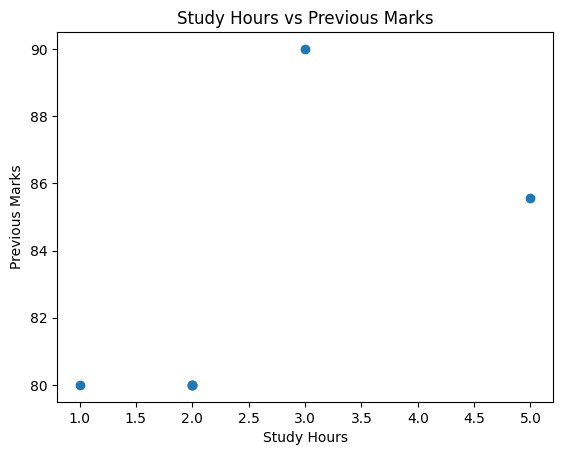

In [ ]:
plt.scatter(data["StudyHours"],data["PreviousMarks"])
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.title("Study Hours vs Previous Marks")
plt.show()

In [ ]:
#Step 7: Feature Engineering (means creating or transforming features to make them more useful for the ML model)
#Create a new feature called performance score

data["PerformanceScore"] = (
0.4 * data["PreviousMarks"] + 0.3 * data["Attendance"] + 0.3 * data["AssignmentScore"]
)

print(data)

   Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result  \
0   18           2          75      80.000000               70   Pass   
1   19           5          88      85.555556               89   Pass   
2   18           3          89      90.000000               65   Pass   
3   20           1          75      80.000000               70   Pass   
4   18           2          77      80.000000               70   Pass   
5   18           2          78      80.000000               70   Pass   

   PerformanceScore  
0         75.500000  
1         87.322222  
2         82.200000  
3         75.500000  
4         76.100000  
5         76.400000  


In [ ]:
print(data.head())

   Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result  \
0   18           2          75      80.000000               70   Pass   
1   19           5          88      85.555556               89   Pass   
2   18           3          89      90.000000               65   Pass   
3   20           1          75      80.000000               70   Pass   
4   18           2          77      80.000000               70   Pass   

   PerformanceScore  
0         75.500000  
1         87.322222  
2         82.200000  
3         75.500000  
4         76.100000  


In [ ]:
# Step 8: Separate features and target

x = data[
    ["StudyHours","Attendance","PreviousMarks","AssignmentScore","PerformanceScore"]
    ]
y = data["Result"]

print(x)
print(y)

   StudyHours  Attendance  PreviousMarks  AssignmentScore  PerformanceScore
0           2          75      80.000000               70         75.500000
1           5          88      85.555556               89         87.322222
2           3          89      90.000000               65         82.200000
3           1          75      80.000000               70         75.500000
4           2          77      80.000000               70         76.100000
5           2          78      80.000000               70         76.400000
0    Pass
1    Pass
2    Pass
3    Pass
4    Pass
5    Pass
Name: Result, dtype: object


In [ ]:
#Step 9: Convert Target into Numerical Value

y = y.map({"Pass":1,"Fail":0})
print(y)

0    1
1    1
2    1
3    1
4    1
5    1
Name: Result, dtype: int64


In [ ]:
#Step 10: Split your Dataset
#80% => training data
#20% => testing data

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
#Step 11: Select an ML algorithm
# Decision tree Classifier
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

In [ ]:
#Step 12: Train the model
model.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
#Step 13: Make predictions
#use test data
y_pred = model.predict(x_test)
print(y_pred)

result = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
print(result)

[1 1]
   Actual  Predicted
0       1          1
1       1          1


In [ ]:
#Step 14: Evaluate the model
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

precision = precision_score(y_test,y_pred)
print("Precision:",precision)

Accuracy: 1.0
Precision: 1.0
